# Student Performance Prediction System — Week 2
## Machine Learning & Finalization

**Workflow covered this week:** Split → Train → Test → Evaluate → Improve → Predict

**Week 2 checklist**
1. Load the model-ready data from Week 1
2. Split into training and testing sets
3. Train several models and compare them
4. Test and evaluate performance
5. Improve the model (hyperparameter tuning)
6. Pick the final model and analyse its errors
7. Classification: predict the Low / Average / High category
8. Save the models
9. Build the prediction system

## 1. Import Libraries & Load Data

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
for folder in ["visualizations", "models", "results"]:
    os.makedirs(folder, exist_ok=True)

In [2]:
df = pd.read_csv("data/model_ready_data.csv")
print("Shape:", df.shape)
df.head()

Shape: (1000, 9)


,Study_Hours_Per_Week,Previous_Exam_Score,Attendance_Percentage,Assignments_Completed_Pct,Sleep_Hours,Tutoring,Parental_Education,Final_Score,Performance
0,12.9,82.5,85.5,78.1,5.1,1,0,57.5,Average
1,13.7,86.4,88.5,56.4,6.9,0,1,81.2,High
2,8.1,50.0,85.7,44.3,6.8,0,0,29.5,Low
3,7.6,65.8,93.6,60.2,4.5,0,1,46.9,Low
4,23.1,61.3,81.0,67.2,8.7,0,2,69.0,Average


We have two possible targets from Week 1:
- **`Final_Score`** (a number) → **regression** problem
- **`Performance`** (Low / Average / High) → **classification** problem

We will solve **both**: the regression model predicts the exact score and the classifier predicts the category.

In [3]:
features = [c for c in df.columns if c not in ("Final_Score", "Performance")]
X = df[features]
y_reg = df["Final_Score"]
y_clf = df["Performance"]
print("Features used:", features)

Features used: ['Study_Hours_Per_Week', 'Previous_Exam_Score', 'Attendance_Percentage', 'Assignments_Completed_Pct', 'Sleep_Hours', 'Tutoring', 'Parental_Education']


## 2. Split Data into Training and Testing Sets
80 % of students are used for training and 20 % are kept aside for testing.
`stratify` keeps the Low / Average / High proportions the same in both sets (important because the *High* class is small).
The test set is **not touched** until the final evaluation.

In [4]:
X_train, X_test, yr_train, yr_test, yc_train, yc_test = train_test_split(
    X, y_reg, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

print("Training set:", X_train.shape, "| Testing set:", X_test.shape)
print("\nCategory share in train:\n", (yc_train.value_counts(normalize=True) * 100).round(1))
print("\nCategory share in test:\n", (yc_test.value_counts(normalize=True) * 100).round(1))

Training set: (800, 7) | Testing set: (200, 7)

Category share in train:
 Performance
Average    60.1
Low        27.1
High       12.8
Name: proportion, dtype: float64

Category share in test:
 Performance
Average    60.0
Low        27.0
High       13.0
Name: proportion, dtype: float64


## 3. Train & Compare Regression Models
Four models are tried, from simple to complex:
- **Linear Regression** – fits a straight-line relationship (features are scaled first)
- **Decision Tree** – learns if/else rules
- **Random Forest** – many trees voting together
- **Gradient Boosting** – trees that fix each other's mistakes

**Metrics**
- **R²** – share of score variation explained (1.0 = perfect, 0 = no better than guessing the average)
- **MAE** – average error in score points
- **RMSE** – like MAE but punishes big mistakes more

**CV R²** is 5-fold cross-validation on the training data only. It shows how stable a model is.

In [5]:
models = {
    "Linear Regression": Pipeline([("scale", StandardScaler()), ("model", LinearRegression())]),
    "Decision Tree":     DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest":     RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

rows = []
for name, model in models.items():
    cv_r2 = cross_val_score(model, X_train, yr_train, cv=5, scoring="r2").mean()
    model.fit(X_train, yr_train)
    pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "CV_R2": round(cv_r2, 3),
        "Test_R2": round(r2_score(yr_test, pred), 3),
        "Test_MAE": round(mean_absolute_error(yr_test, pred), 2),
        "Test_RMSE": round(np.sqrt(mean_squared_error(yr_test, pred)), 2),
    })

results = pd.DataFrame(rows).sort_values("CV_R2", ascending=False).reset_index(drop=True)
results

,Model,CV_R2,Test_R2,Test_MAE,Test_RMSE
0,Linear Regression,0.740,0.829,3.79,4.76
1,Gradient Boosting,0.673,0.763,4.41,5.61
2,Random Forest,0.664,0.739,4.78,5.89
3,Decision Tree,0.457,0.521,6.35,7.97


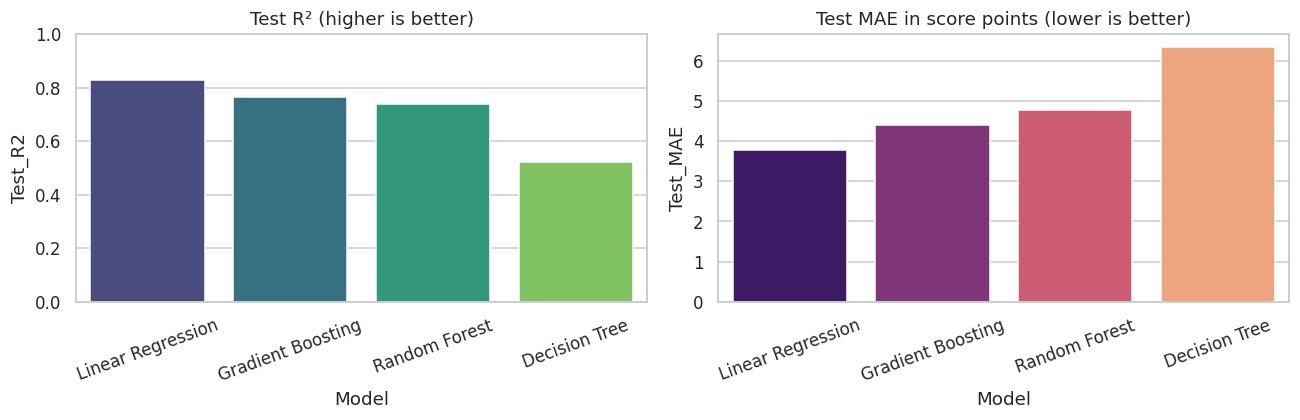

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=results, x="Model", y="Test_R2", hue="Model", palette="viridis", legend=False, ax=ax[0])
ax[0].set_title("Test R² (higher is better)"); ax[0].set_ylim(0, 1); ax[0].tick_params(axis="x", rotation=20)
sns.barplot(data=results, x="Model", y="Test_MAE", hue="Model", palette="magma", legend=False, ax=ax[1])
ax[1].set_title("Test MAE in score points (lower is better)"); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig("visualizations/10_model_comparison.png", dpi=150)
plt.show()

**Observation:** The simple Linear Regression beats the more complex models. This makes sense: the scores are driven by
mostly *straight-line* relationships (more study hours → higher score), which a linear model captures directly,
while tree models need many splits to approximate a straight line. A more complex model is not always a better model.

## 4. Improve the Model — Hyperparameter Tuning
`GridSearchCV` tries many settings with cross-validation on the **training set only** and keeps the best.
We tune Gradient Boosting (the best tree model) and Ridge Regression (linear model with regularisation).

In [7]:
gb_search = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    {"n_estimators": [100, 200], "max_depth": [2, 3], "learning_rate": [0.03, 0.1]},
    cv=5, scoring="r2").fit(X_train, yr_train)

ridge_search = GridSearchCV(
    Pipeline([("scale", StandardScaler()), ("model", Ridge())]),
    {"model__alpha": [0.01, 0.1, 1, 10, 100]},
    cv=5, scoring="r2").fit(X_train, yr_train)

print("Best Gradient Boosting:", gb_search.best_params_, "| CV R2 =", round(gb_search.best_score_, 3))
print("Best Ridge            :", ridge_search.best_params_, "| CV R2 =", round(ridge_search.best_score_, 3))

Best Gradient Boosting: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200} | CV R2 = 0.684
Best Ridge            : {'model__alpha': 1} | CV R2 = 0.74


In [8]:
tuned = {"Gradient Boosting (tuned)": gb_search.best_estimator_,
         "Ridge (tuned)": ridge_search.best_estimator_}
for name, model in tuned.items():
    pred = model.predict(X_test)
    results.loc[len(results)] = {
        "Model": name,
        "CV_R2": round(cross_val_score(model, X_train, yr_train, cv=5, scoring="r2").mean(), 3),
        "Test_R2": round(r2_score(yr_test, pred), 3),
        "Test_MAE": round(mean_absolute_error(yr_test, pred), 2),
        "Test_RMSE": round(np.sqrt(mean_squared_error(yr_test, pred)), 2)}

results = results.sort_values("CV_R2", ascending=False).reset_index(drop=True)
results.to_csv("results/regression_model_results.csv", index=False)
results

,Model,CV_R2,Test_R2,Test_MAE,Test_RMSE
0,Linear Regression,0.740,0.829,3.79,4.76
1,Ridge (tuned),0.740,0.829,3.79,4.76
2,Gradient Boosting (tuned),0.684,0.794,4.04,5.23
3,Gradient Boosting,0.673,0.763,4.41,5.61
4,Random Forest,0.664,0.739,4.78,5.89
5,Decision Tree,0.457,0.521,6.35,7.97


## 5. Choose the Final Regression Model
The final model is chosen by **cross-validation score on training data** (not by looking at the test set), to avoid
"peeking" at the test data. Then it is evaluated once on the test set.

In [9]:
all_models = {**models, **tuned}
best_name = results.iloc[0]["Model"]
final_reg = all_models[best_name]

pred = final_reg.predict(X_test)
final_metrics = {
    "model": best_name,
    "R2": round(r2_score(yr_test, pred), 3),
    "MAE": round(mean_absolute_error(yr_test, pred), 2),
    "RMSE": round(float(np.sqrt(mean_squared_error(yr_test, pred))), 2),
}
print("Final regression model:", best_name)
print(final_metrics)

Final regression model: Linear Regression
{'model': 'Linear Regression', 'R2': 0.829, 'MAE': 3.79, 'RMSE': 4.76}


### 5.1 Actual vs Predicted scores and errors

Average error: 3.79 score points
90% of predictions are within 7.8 points of the real score


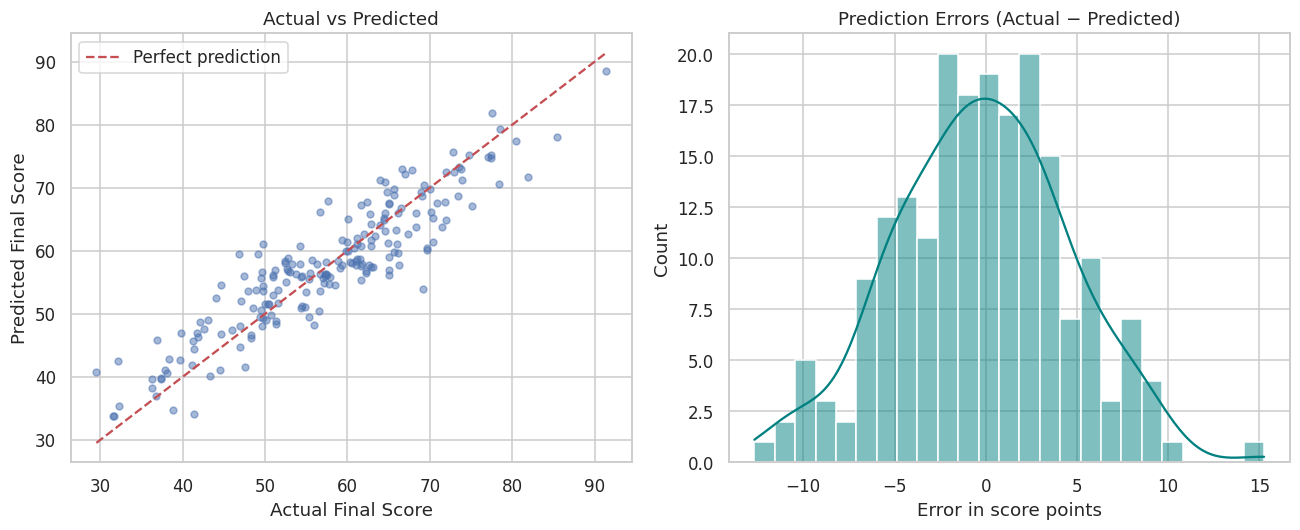

In [10]:
residuals = yr_test - pred
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(yr_test, pred, alpha=0.5, s=20)
lims = [min(yr_test.min(), pred.min()), max(yr_test.max(), pred.max())]
ax[0].plot(lims, lims, "r--", label="Perfect prediction")
ax[0].set_xlabel("Actual Final Score"); ax[0].set_ylabel("Predicted Final Score")
ax[0].set_title("Actual vs Predicted"); ax[0].legend()
sns.histplot(residuals, bins=25, kde=True, ax=ax[1], color="teal")
ax[1].set_title("Prediction Errors (Actual − Predicted)"); ax[1].set_xlabel("Error in score points")
plt.tight_layout()
plt.savefig("visualizations/11_actual_vs_predicted.png", dpi=150)
plt.show()
print("Average error:", round(float(residuals.abs().mean()), 2), "score points")
print("90% of predictions are within", round(float(residuals.abs().quantile(0.9)), 1), "points of the real score")

### 5.2 Which features matter most to the final model?

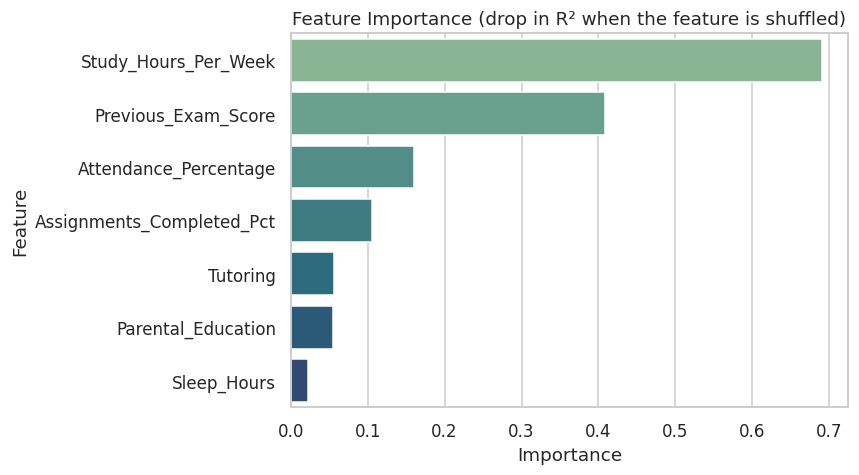

Study_Hours_Per_Week         0.690
Previous_Exam_Score          0.408
Attendance_Percentage        0.160
Assignments_Completed_Pct    0.106
Tutoring                     0.056
Parental_Education           0.055
Sleep_Hours                  0.022
dtype: float64

In [11]:
perm = permutation_importance(final_reg, X_test, yr_test, n_repeats=15, random_state=42)
importance = pd.Series(perm.importances_mean, index=features).sort_values(ascending=False)

plt.figure(figsize=(8, 4.5))
sns.barplot(x=importance.values, y=importance.index, hue=importance.index, palette="crest", legend=False)
plt.title("Feature Importance (drop in R² when the feature is shuffled)")
plt.xlabel("Importance"); plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("visualizations/12_final_feature_importance.png", dpi=150)
plt.show()
importance.round(3)

## 6. Classification — Predict Low / Average / High
Besides the exact score, the system should say whether the student is **Low**, **Average** or **High**.
`class_weight="balanced"` gives the small *High* group more weight so the model does not ignore it.

In [12]:
clf_models = {
    "Logistic Regression": Pipeline([("scale", StandardScaler()),
                                     ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced"),
}
clf_rows = []
for name, model in clf_models.items():
    cv_acc = cross_val_score(model, X_train, yc_train, cv=5, scoring="accuracy").mean()
    model.fit(X_train, yc_train)
    acc = accuracy_score(yc_test, model.predict(X_test))
    clf_rows.append({"Model": name, "CV_Accuracy": round(cv_acc, 3), "Test_Accuracy": round(acc, 3)})

clf_results = pd.DataFrame(clf_rows).sort_values("CV_Accuracy", ascending=False).reset_index(drop=True)
clf_results.to_csv("results/classification_model_results.csv", index=False)
clf_results

,Model,CV_Accuracy,Test_Accuracy
0,Random Forest,0.742,0.77
1,Logistic Regression,0.734,0.75


In [13]:
best_clf_name = clf_results.iloc[0]["Model"]
final_clf = clf_models[best_clf_name]
clf_pred = final_clf.predict(X_test)
print("Final classifier:", best_clf_name)
print()
print(classification_report(yc_test, clf_pred, labels=["Low", "Average", "High"]))

Final classifier: Random Forest

              precision    recall  f1-score   support

         Low       0.81      0.63      0.71        54
     Average       0.75      0.92      0.83       120
        High       0.83      0.38      0.53        26

    accuracy                           0.77       200
   macro avg       0.80      0.64      0.69       200
weighted avg       0.78      0.77      0.76       200


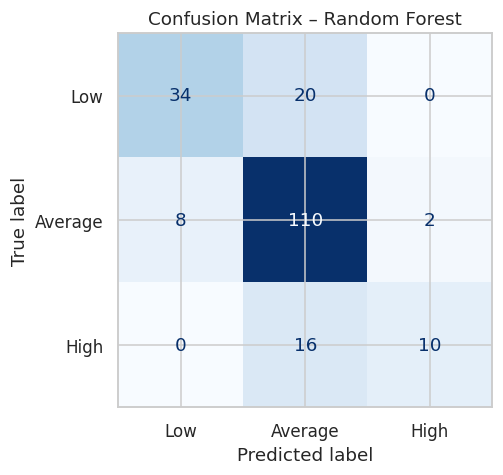

In [14]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(yc_test, clf_pred, labels=["Low", "Average", "High"],
                                        cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"Confusion Matrix – {best_clf_name}")
plt.tight_layout()
plt.savefig("visualizations/13_confusion_matrix.png", dpi=150)
plt.show()

**How to read it:** each row is the *real* category and each column is the *predicted* one. Most mistakes happen between
neighbouring categories (for example Average ↔ High), which is expected, because a student near a boundary
(such as a score of 69 vs 71) can easily fall on either side.

## 7. Save the Final Models

In [15]:
final_reg.fit(X_train, yr_train)   # already fitted; refit keeps things explicit
joblib.dump(final_reg, "models/final_regression_model.joblib")
joblib.dump(final_clf, "models/final_classifier.joblib")
joblib.dump(features, "models/feature_order.joblib")

summary = {
    "regression": final_metrics,
    "classification": {"model": best_clf_name,
                       "accuracy": round(accuracy_score(yc_test, clf_pred), 3)},
    "train_rows": int(len(X_train)), "test_rows": int(len(X_test)),
}
json.dump(summary, open("results/final_results.json", "w"), indent=2)
summary

{'regression': {'model': 'Linear Regression', 'R2': 0.829, 'MAE': 3.79, 'RMSE': 4.76}, 'classification': {'model': 'Random Forest', 'accuracy': 0.77}, 'train_rows': 800, 'test_rows': 200}

## 8. The Student Performance Prediction System
Enter a student's details and the system returns a **predicted final score**, a **category**, and a
simple **advice message**. Parental education is entered as text (`High School`, `Bachelor`, `Master`, `PhD`) and tutoring as `Yes`/`No`.

In [16]:
EDU_MAP = {"high school": 0, "bachelor": 1, "master": 2, "phd": 3}

def predict_student(study_hours, previous_score, attendance, assignments_pct,
                    sleep_hours, tutoring, parental_education):
    row = pd.DataFrame([{
        "Study_Hours_Per_Week": study_hours,
        "Previous_Exam_Score": previous_score,
        "Attendance_Percentage": attendance,
        "Assignments_Completed_Pct": assignments_pct,
        "Sleep_Hours": sleep_hours,
        "Tutoring": 1 if str(tutoring).strip().lower() in ("yes", "y", "1", "true") else 0,
        "Parental_Education": EDU_MAP[str(parental_education).strip().lower()],
    }])[features]

    score = float(np.clip(final_reg.predict(row)[0], 0, 100))
    category = final_clf.predict(row)[0]
    proba = dict(zip(final_clf.classes_, final_clf.predict_proba(row)[0]))

    tips = []
    if study_hours < 10: tips.append("increase weekly study time")
    if attendance < 75: tips.append("improve class attendance")
    if assignments_pct < 70: tips.append("complete more assignments")
    if sleep_hours < 6: tips.append("get more sleep")
    if tips:
        advice = "Focus areas: " + ", ".join(tips) + "."
    elif category == "High":
        advice = "Keep up the good work!"
    else:
        advice = "Raising study hours and assignment completion would help move up a level."

    print(f"Predicted final score : {score:.1f} / 100")
    print(f"Predicted category    : {category}")
    print("Category probabilities:", {k: f"{v:.0%}" for k, v in proba.items()})
    print("Advice                :", advice)
    return score, category

In [17]:
print("--- Strong student ---")
predict_student(22, 85, 95, 92, 7.5, "Yes", "Master")
print("\n--- Average student ---")
predict_student(14, 62, 80, 75, 7, "No", "Bachelor")
print("\n--- Struggling student ---")
predict_student(4, 40, 55, 40, 5, "No", "High School")

--- Strong student ---
Predicted final score : 87.3 / 100
Predicted category    : High
Category probabilities: {'Average': '10%', 'High': '90%', 'Low': '0%'}
Advice                : Keep up the good work!

--- Average student ---
Predicted final score : 56.5 / 100
Predicted category    : Average
Category probabilities: {'Average': '75%', 'High': '6%', 'Low': '19%'}
Advice                : Raising study hours and assignment completion would help move up a level.

--- Struggling student ---
Predicted final score : 21.0 / 100
Predicted category    : Low
Category probabilities: {'Average': '12%', 'High': '0%', 'Low': '88%'}
Advice                : Focus areas: increase weekly study time, improve class attendance, complete more assignments, get more sleep.


(21.01678450660085, 'Low')

You can also run the system from the command line without Jupyter: `python predict.py`
(it asks for the same inputs and loads the saved models).

## 9. Final Results & Conclusion
- The data was split 80 / 20 (stratified) and several models were compared with cross-validation.
- **Final regression model: Linear Regression** — on the untouched test set it reaches **R² ≈ 0.83**, with an average error (MAE) of about **3.8 score points** and RMSE of about 4.8.
- **Final classifier: Random Forest** — **77 % accuracy** on the test set. It is strong on *Average* (recall 92 %) and *Low* (63 %), but finds only about 38 % of *High* students.
- A simple linear model performed best because the relationship between study habits and score is largely linear. Tuning helped the tree models but did not beat it.
- The weakest class is **High** (only ~13 % of students), so the classifier tends to label them *Average*. Collecting more High-performing examples, or using the regression score to decide the category, would help.

**Limitations**
- The dataset is **synthetic**, so these results show that the workflow works, not how real students behave.
- Real data would include noisier factors (motivation, health, teaching quality) and would likely give lower accuracy.

**Possible future improvements:** collect real data, add more features, try other models, and build a small web app (for example with Streamlit) around the prediction system.